C:\Users\Harini.S\AppData\Local\Temp\ipykernel_30812\3760384887.py:6: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("archive/cleaned_amazon_sales.csv")


Top 10 States by Total Orders:
ship-state
MAHARASHTRA       22260
KARNATAKA         17326
TAMIL NADU        11483
TELANGANA         11330
UTTAR PRADESH     10638
DELHI              6967
KERALA             6585
WEST BENGAL        5963
ANDHRA PRADESH     5430
GUJARAT            4489
dtype: int64

Top 10 States by Revenue:
ship-state
MAHARASHTRA       14053669.14
KARNATAKA         11044974.37
TELANGANA          7335880.65
UTTAR PRADESH      7234697.08
TAMIL NADU         6923420.11
DELHI              4587202.46
KERALA             4092797.58
WEST BENGAL        3759560.44
ANDHRA PRADESH     3446706.72
HARYANA            3019427.99
Name: Amount, dtype: float64

State-wise Order Count and Revenue:
                        Order_Count      Revenue
ship-state                                      
ANDAMAN & NICOBAR               257    167193.62
ANDHRA PRADESH                 5430   3446706.72
APO                               1       605.00
AR                                1       493.00
ARUNACH

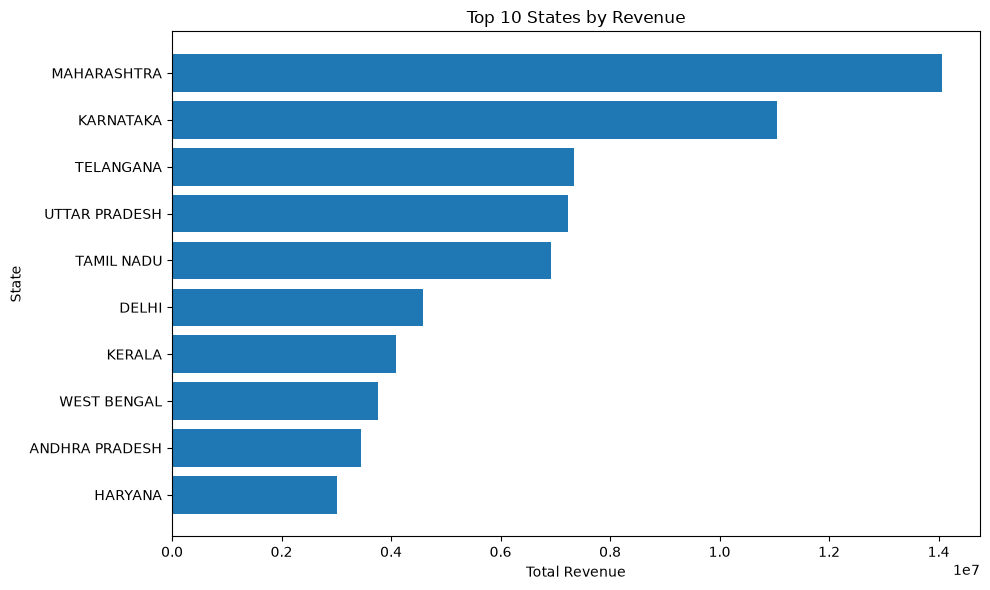

In [ ]:
# Task 5: Geographical Sales Analysis
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("archive/cleaned_amazon_sales.csv")

state_orders = df.groupby("ship-state").size().sort_values(ascending=False)

print("Top 10 States by Total Orders:")
print(state_orders.head(10))

state_revenue = df.groupby("ship-state")["Amount"].sum().sort_values(ascending=False)

print("\nTop 10 States by Revenue:")
print(state_revenue.head(10))

state_analysis = pd.DataFrame({
    "Order_Count": state_orders,
    "Revenue": state_revenue
})

print("\nState-wise Order Count and Revenue:")
print(state_analysis)


# 4. Identify states with high orders but low revenue
# Use median as the comparison point

high_order_low_revenue = state_analysis[
    (state_analysis["Order_Count"] > state_analysis["Order_Count"].median()) &
    (state_analysis["Revenue"] < state_analysis["Revenue"].median())
]

print("\nStates with High Order Count but Low Revenue:")
print(high_order_low_revenue)


# 5.  bar chart 

top_10_revenue = state_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_revenue.index,
    top_10_revenue.values
)

plt.title("Top 10 States by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("State")

plt.tight_layout()
plt.show()